## Tp4 - Apprentisage par Renforcement


In [1]:
import gymnasium as gym
from stable_baselines3 import PPO
# -------------------------------
# Créer l'environnement
# -------------------------------
env = gym.make("CartPole-v1", render_mode="human") # render_mode="human" pour
# -------------------------------
# Définir le modèle RL
# -------------------------------
# PPO : Proximal Policy Optimization (algorithme Actor-Critic)
model = PPO("MlpPolicy", env, verbose=1)
# -------------------------------
# Entraîner l'agent
# -------------------------------
print("Entraînement en cours...")
model.learn(total_timesteps=10000) # tu peux augmenter pour un meilleur
print("Entraînement terminé !")
# -------------------------------
# Tester l'agent entraîné
# -------------------------------

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entraînement en cours...


/opt/anaconda3/envs/rl_tp/lib/python3.9/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21       |
|    ep_rew_mean     | 21       |
| time/              |          |
|    fps             | 33       |
|    iterations      | 1        |
|    time_elapsed    | 60       |
|    total_timesteps | 2048     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 26           |
|    ep_rew_mean          | 26           |
| time/                   |              |
|    fps                  | 38           |
|    iterations           | 2            |
|    time_elapsed         | 106          |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0085403295 |
|    clip_fraction        | 0.0904       |
|    clip_range           | 0.2          |
|    entropy_loss         | -0.686       |
|    explained_variance   | -0.00274     |
|    learning_r

In [4]:
import gymnasium as gym
from stable_baselines3 import PPO
import matplotlib.pyplot as plt
# -------------------------------
# Créer l'environnement
# -------------------------------
env = gym.make("CartPole-v1", render_mode="human") # voir la simulation
# -------------------------------
# Définir le modèle RL
# -------------------------------
model = PPO("MlpPolicy", env, verbose=1)
# -------------------------------
# Entraîner l'agent
# -------------------------------
total_timesteps = 10000
print("Entraînement en cours...")
model.learn(total_timesteps=total_timesteps)
print("Entraînement terminé !")
# -------------------------------
# Tester l'agent et suivre les récompenses
# -------------------------------
num_episodes = 5
rewards_list = []
for ep in range(num_episodes):
    obs, info = env.reset()
    done = False
    total_reward = 0
    while not done:
        env.render() # simulation visible
        action, _= model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        total_reward += reward
    rewards_list.append(total_reward)
    print(f"Épisode {ep+1} - Récompense : {total_reward}")
env.close()

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entraînement en cours...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 21.9     |
|    ep_rew_mean     | 21.9     |
| time/              |          |
|    fps             | 43       |
|    iterations      | 1        |
|    time_elapsed    | 47       |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 28.4        |
|    ep_rew_mean          | 28.4        |
| time/                   |             |
|    fps                  | 44          |
|    iterations           | 2           |
|    time_elapsed         | 92          |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008153887 |
|    clip_fraction        | 0.0959      |
|    clip_range           | 0.2      

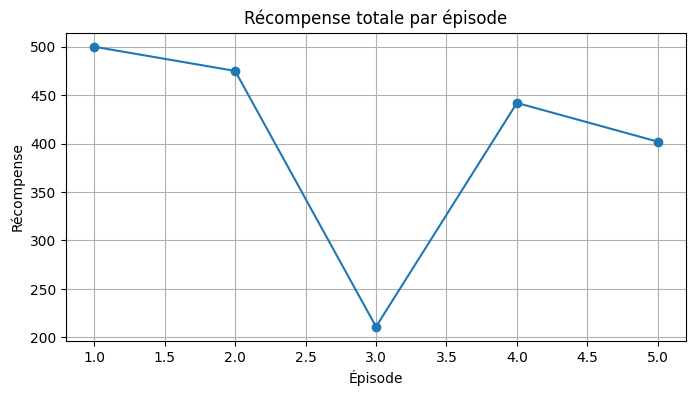

: 

In [ ]:
plt.figure(figsize=(8,4))
plt.plot(range(1, num_episodes+1), rewards_list, marker='o')
plt.title("Récompense totale par épisode")
plt.xlabel("Épisode")
plt.ylabel("Récompense")
plt.grid(True)
plt.show()

**Exemple 1 (Entraînement seul) :**

* L'agent PPO apprend progressivement sur `CartPole-v1` : la récompense moyenne (`ep_rew_mean`) passe de **21** à **59,1** en 5 itérations (`10 240` pas).


* Les métriques confirment un début d'apprentissage stable : `explained_variance` monte à **0,289** (meilleures prédictions) et `entropy_loss` passe de **-0,686** à **-0,619** (moins de hasard).


* L'entraînement est lent (**240 s**, ~40 FPS) à cause de l'affichage activé (`render_mode="human"`).



**Exemple 2 (Entraînement + Test sur 5 épisodes) :**

* L'entraînement suit une courbe similaire (`ep_rew_mean` de **21,9** à **58,5** en **270 s**).


* En phase de test, l'agent obtient des scores élevés : **500**, **475**, **211**, **442** et **402** (moyenne de **406/500**), montrant qu'il maîtrise déjà bien l'équilibre malgré une légère instabilité à l'épisode 3.



**Différence entraînement vs test :** Les scores en test sont bien meilleurs car l'agent agit en mode déterministe (`deterministic=True`, sans exploration aléatoire), alors que `ep_rew_mean` pendant l'entraînement inclut les anciens épisodes où l'agent était encore débutant.